# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [2]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [3]:
# Replace None with your code
califonia_LE_products = pd.read_sql(
    """
SELECT c.customerName, c.contactFirstName, c.contactLastName, c.phone, CAST(c.creditLimit AS REAL) AS creditLimit
FROM customers AS c
WHERE c.state = 'CA' AND creditLimit > 25000.00
    """, conn
)
califonia_LE_products

,customerName,contactFirstName,contactLastName,phone,creditLimit
0,Mini Gifts Distributors Ltd.,Susan,Nelson,4155551450,210500.0
1,Mini Wheels Co.,Julie,Murphy,6505555787,64600.0
2,Technics Stores Inc.,Juri,Hashimoto,6505556809,84600.0
3,Toys4GrownUps.com,Julie,Young,6265557265,90700.0
4,Boards & Toys Co.,Mary,Young,3105552373,11000.0
5,Collectable Mini Designs Co.,Valarie,Thompson,7605558146,105000.0
6,Corporate Gift Ideas Co.,Julie,Brown,6505551386,105000.0
7,"Men 'R' US Retailers, Ltd.",Brian,Chandler,2155554369,57700.0
8,The Sharp Gifts Warehouse,Sue,Frick,4085553659,77600.0
9,West Coast Collectables Co.,Steve,Thompson,3105553722,55400.0


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [4]:
# Replace None with your code
international_collection_campaign = pd.read_sql(
    """
SELECT c.customerName, c.contactFirstName, c.contactLastName, c.phone, c.city, c.country
FROM customers AS c
WHERE NOT c.country = 'USA' AND c.customerName LIKE '%collect%'
    """, conn
)

international_collection_campaign

,customerName,contactFirstName,contactLastName,phone,city,country
0,"Australian Collectors, Co.",Peter,Ferguson,03 9520 4555,Melbourne,Australia
1,"Clover Collections, Co.",Dean,Cassidy,+353 1862 1555,Dublin,Ireland
2,"UK Collectables, Ltd.",Elizabeth,Devon,(171) 555-2282,Liverpool,UK
3,"King Kong Collectables, Co.",Mike,Gao,+852 2251 1555,Central Hong Kong,Hong Kong
4,Heintze Collectables,Palle,Ibsen,86 21 3555,Århus,Denmark
5,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,(604) 555-4555,Tsawassen,Canada
6,BG&E Collectables,Ed,Harrison,+41 26 425 50 01,Fribourg,Switzerland
7,Reims Collectables,Paul,Henriot,26.47.1555,Reims,France
8,Precious Collectables,Braun,Urs,0452-076555,Bern,Switzerland
9,Salzburg Collectables,Georg,Pipps,6562-9555,Salzburg,Austria


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

- The first part of the statement `WHERE NOT c.country = 'USA'` is to ensure that we only get our customers from our international market by filtering out the US market.
- The second part of the statement `AND c.customerName LIKE '%collect%'` is to ensure that we are able to stick to our theme of ***'Collect them all'*** by checking if *'collect'* is in the customer`s name

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [5]:
# Replace None with your code
credit_and_inventory_policy = pd.read_sql(
    """
SELECT c.state, ROUND(AVG(c.creditLimit),2) AS average_credit_limit
FROM customers AS c
WHERE c.country = 'USA'
GROUP BY c.state
ORDER BY average_credit_limit DESC
    """, conn
)
credit_and_inventory_policy

,state,average_credit_limit
0,NH,114200.00
1,NY,89966.67
2,PA,84766.67
3,CA,83854.55
4,NV,71800.00
5,MA,70755.56
6,CT,57350.00
7,NJ,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

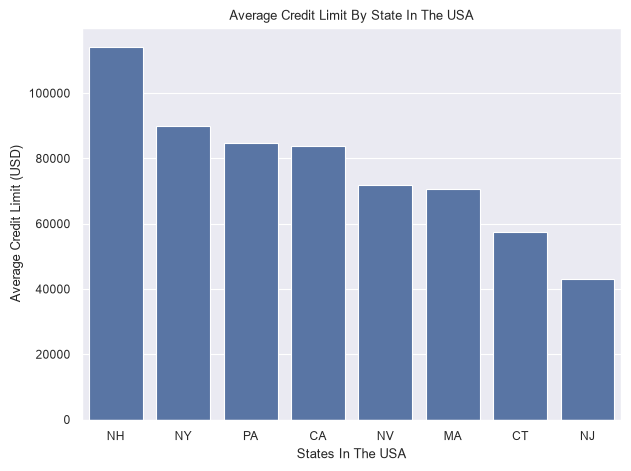

In [6]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
sns.set_context('notebook')
sns.set_theme('paper')
sns.set_style('darkgrid')
credit_plot = sns.barplot(
    data=credit_and_inventory_policy,
    x='state',
    y='average_credit_limit'
)
credit_plot.set(
    xlabel = 'States In The USA',
    ylabel = 'Average Credit Limit (USD)',
    title = 'Average Credit Limit By State In The USA'
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [7]:
# Replace None with your code
top_10_customers = pd.read_sql(
    """
SELECT c.customerName, c.phone, c.country, SUM(p.amount) AS sum_of_payments
FROM customers AS c
INNER JOIN payments AS p ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber
ORDER BY sum_of_payments DESC
LIMIT 10
    """, conn
)
top_10_customers

,customerName,phone,country,sum_of_payments
0,Euro+ Shopping Channel,(91) 555 94 44,Spain,715738.98
1,Mini Gifts Distributors Ltd.,4155551450,USA,584188.24
2,"Australian Collectors, Co.",03 9520 4555,Australia,180585.07
3,Muscle Machine Inc,2125557413,USA,177913.95
4,"Dragon Souveniers, Ltd.",+65 221 7555,Singapore,156251.03
5,"Down Under Souveniers, Inc",+64 9 312 5555,New Zealand,154622.08
6,"AV Stores, Co.",(171) 555-1555,UK,148410.09
7,"Anna's Decorations, Ltd",02 9936 8555,Australia,137034.22
8,Corporate Gift Ideas Co.,6505551386,USA,132340.78
9,"Saveley & Henriot, Co.",78.32.5555,France,130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

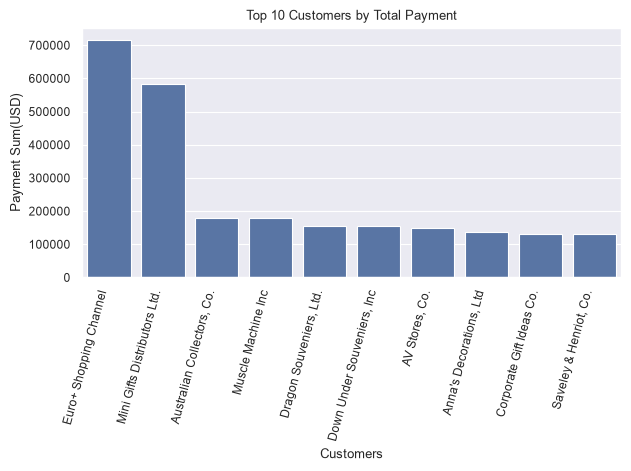

In [8]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
sns.set_context('notebook')
sns.set_theme('paper')
sns.set_style('darkgrid')
customer_plot = sns.barplot(
    data=top_10_customers,
    x='customerName',
    y='sum_of_payments'
)
customer_plot.set(
    xlabel = 'Customers',
    ylabel = 'Payment Sum(USD)',
    title = 'Top 10 Customers by Total Payment'
)
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [9]:
# Replace None with you code
top_customers_product = pd.read_sql(
    """
SELECT c.customerName, p.productName, SUM(od.quantityOrdered) AS total_quantities
FROM customers AS c
JOIN orders AS o ON c.customerNumber = o.customerNumber
JOIN orderDetails AS od ON o.orderNumber = od.orderNumber
JOIN products AS p ON od.productCode = p.productCode
GROUP BY c.customerName, p.productName
HAVING total_quantities >= 10
ORDER BY total_quantities ASC
    """, conn
)
top_customers_product

,customerName,productName,total_quantities
0,"Extreme Desk Decorations, Ltd",1961 Chevrolet Impala,10
1,Petit Auto,1913 Ford Model T Speedster,10
2,La Rochelle Gifts,1954 Greyhound Scenicruiser,11
3,Tekni Collectables Inc.,American Airlines: B767-300,11
4,The Sharp Gifts Warehouse,1969 Chevrolet Camaro Z28,13
...,...,...,...
2526,Euro+ Shopping Channel,2002 Chevy Corvette,174
2527,Euro+ Shopping Channel,1957 Chevy Pickup,183
2528,Euro+ Shopping Channel,1970 Dodge Coronet,197
2529,Euro+ Shopping Channel,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [10]:
# Replace None with your code
products_and_product_line = pd.read_sql(
    """
SELECT p.productLine AS 'Product Line', COUNT(od.productCode) AS 'Number Of Products', SUM(od.quantityOrdered) AS 'Total Quantity Ordered'
FROM products AS p
JOIN orderdetails AS od ON p.productCode = od.productCode
GROUP BY p.productLine
    """, conn
)
products_and_product_line

,Product Line,Number Of Products,Total Quantity Ordered
0,Classic Cars,1010,35582
1,Motorcycles,359,12778
2,Planes,336,11872
3,Ships,245,8532
4,Trains,81,2818
5,Trucks and Buses,308,11001
6,Vintage Cars,657,22933


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

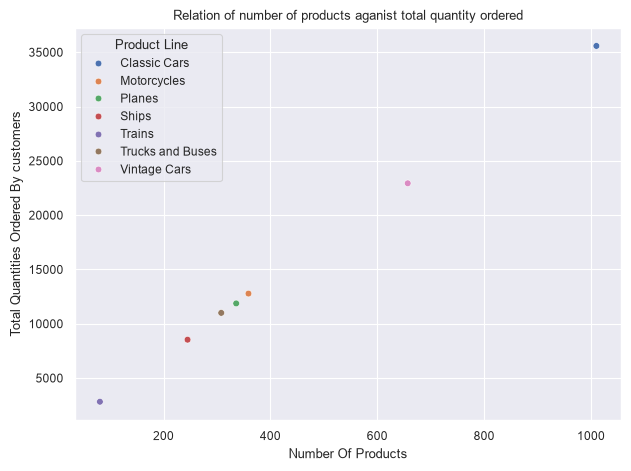

In [11]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
sns.set_context('notebook')
sns.set_theme('paper')
sns.set_style('darkgrid')

product_plot = sns.scatterplot(
    data=products_and_product_line,
    x='Number Of Products',
    y='Total Quantity Ordered',
    hue='Product Line'
)
product_plot.set(
    xlabel='Number Of Products',
    ylabel='Total Quantities Ordered By customers',
    title='Relation of number of products aganist total quantity ordered'
)
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

- This is the relationship between the number of products per product line and the volumes of the products per product line ordered.
- The product line `Classic Cars` is the product line with the most products that has the largest quantities ordered.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [12]:
# Replace None with your code
remote = pd.read_sql_query(
    """
SELECT
    e.firstName || " " ||e.lastName AS "Employee Name",
    e.jobTitle,
    m.firstName || " " ||m.lastName AS 'Supervisor Name',
    o.city
FROM employees AS e
LEFT JOIN offices AS o ON e.officeCode = o.officeCode
LEFT JOIN employees AS m ON e.employeeNumber = m.reportsTo
WHERE e.officeCode IN (
    SELECT e.officeCode
    FROM employees AS e
    GROUP BY e.officeCode
    HAVING COUNT(e.officeCode) < 5
)
    """, conn
)
remote

,Employee Name,jobTitle,Supervisor Name,city
0,William Patterson,Sales Manager (APAC),Andy Fixter,Sydney
1,William Patterson,Sales Manager (APAC),Tom King,Sydney
2,William Patterson,Sales Manager (APAC),Peter Marsh,Sydney
3,Julie Firrelli,Sales Rep,NaN,Boston
4,Steve Patterson,Sales Rep,NaN,Boston
5,Foon Yue Tseng,Sales Rep,NaN,NYC
6,George Vanauf,Sales Rep,NaN,NYC
7,Larry Bott,Sales Rep,NaN,London
8,Barry Jones,Sales Rep,NaN,London
9,Andy Fixter,Sales Rep,NaN,Sydney


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

- The subquery is used to get the number of employees in offices that have less than 5 employees through the `HAVING COUNT(e.officeCode) < 5` statement in order to get which employees, who they report to and which city office they are located

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [13]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [14]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [15]:
# Begin your code here

conn = sqlite3.connect('im.db')


In [39]:
directors = pd.read_sql(
    """
SELECT DISTINCT
    mb.movie_id,
    pe.primary_name AS director,
    mb.primary_title,
    mb.original_title,
    mb.start_year,
    mb.runtime_minutes,
    mb.genres,
    mr.averagerating,
    mr.numvotes
FROM movie_basics AS mb
LEFT JOIN directors AS dr ON mb.movie_id = dr.movie_id
LEFT JOIN persons AS pe ON dr.person_id = pe.person_id
LEFT JOIN movie_ratings AS mr ON mb.movie_id = mr.movie_id
WHERE mb.start_year < 2019
    """, conn
)

directors.head()

,movie_id,director,primary_title,original_title,start_year,runtime_minutes,genres,averagerating,numvotes
0,tt0063540,Harnam Singh Rawail,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama",7.0,77.0
1,tt0069049,Orson Welles,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama,6.9,4517.0
2,tt0069204,Hrishikesh Mukherjee,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama",6.1,13.0
3,tt0100275,Raoul Ruiz,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy",6.5,119.0
4,tt0100275,Valeria Sarmiento,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy",6.5,119.0


In [17]:
writers = pd.read_sql(
    """
SELECT DISTINCT
    mb.movie_id,
    pe.primary_name AS writers,
    mb.primary_title,
    mb.original_title,
    mb.start_year,
    mb.runtime_minutes,
    mb.genres,
    mr.averagerating,
    mr.numvotes
FROM movie_basics AS mb
LEFT JOIN writers AS wr ON mb.movie_id = wr.movie_id
LEFT JOIN persons AS pe ON wr.person_id = pe.person_id
LEFT JOIN movie_ratings AS mr ON mb.movie_id = mr.movie_id
WHERE mb.start_year < 2019
    """, conn
)
writers.head()

,movie_id,writers,primary_title,original_title,start_year,runtime_minutes,genres,averagerating,numvotes
0,tt0063540,Abrar Alvi,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama",7.0,77.0
1,tt0063540,Gulzar,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama",7.0,77.0
2,tt0063540,Mahasweta Devi,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama",7.0,77.0
3,tt0063540,Anjana Rawail,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama",7.0,77.0
4,tt0069049,Orson Welles,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama,6.9,4517.0


In [18]:
directors.info()

<class 'pandas.DataFrame'>
RangeIndex: 158562 entries, 0 to 158561
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   movie_id         158562 non-null  str    
 1   director         153400 non-null  str    
 2   primary_title    158562 non-null  str    
 3   original_title   158542 non-null  str    
 4   start_year       158562 non-null  int64  
 5   runtime_minutes  127952 non-null  float64
 6   genres           152975 non-null  str    
 7   averagerating    84264 non-null   float64
 8   numvotes         84264 non-null   float64
dtypes: float64(3), int64(1), str(5)
memory usage: 10.9 MB


In [40]:
directors.describe()

,start_year,runtime_minutes,averagerating,numvotes
count,158562.000000,127952.000000,84264.000000,8.426400e+04
mean,2014.295102,86.492622,6.331368,3.395099e+03
std,2.528018,224.591768,1.472927,2.962540e+04
min,2010.000000,1.000000,1.000000,5.000000e+00
25%,2012.000000,70.000000,5.500000,1.400000e+01
50%,2014.000000,86.000000,6.500000,4.700000e+01
75%,2016.000000,99.000000,7.400000,2.650000e+02
max,2018.000000,51420.000000,10.000000,1.841066e+06


In [41]:
directors.isna().sum()

movie_id               0
director            5162
primary_title          0
original_title        20
start_year             0
runtime_minutes    30610
genres              5587
averagerating      74298
numvotes           74298
dtype: int64

In [42]:
directors = directors[(directors['runtime_minutes'] <= 300) & (directors['runtime_minutes'] >= 60)]
directors.describe()

,start_year,runtime_minutes,averagerating,numvotes
count,105878.000000,105878.000000,71036.000000,7.103600e+04
mean,2014.205113,92.923997,6.272469,4.017168e+03
std,2.513363,21.652654,1.445125,3.222656e+04
min,2010.000000,60.000000,1.000000,5.000000e+00
25%,2012.000000,80.000000,5.400000,1.700000e+01
50%,2014.000000,90.000000,6.400000,6.600000e+01
75%,2016.000000,102.000000,7.300000,3.620000e+02
max,2018.000000,300.000000,10.000000,1.841066e+06


In [21]:
writers.info()

<class 'pandas.DataFrame'>
RangeIndex: 199940 entries, 0 to 199939
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   movie_id         199940 non-null  str    
 1   writers          166195 non-null  str    
 2   primary_title    199940 non-null  str    
 3   original_title   199921 non-null  str    
 4   start_year       199940 non-null  int64  
 5   runtime_minutes  164613 non-null  float64
 6   genres           194029 non-null  str    
 7   averagerating    118655 non-null  float64
 8   numvotes         118655 non-null  float64
dtypes: float64(3), int64(1), str(5)
memory usage: 13.7 MB


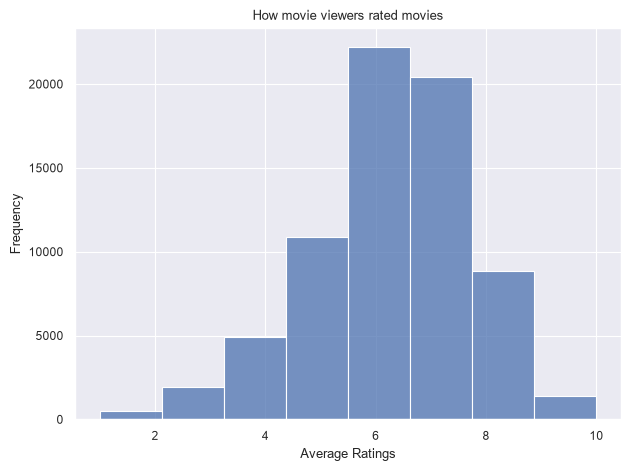

In [22]:
sns.set_context('notebook')
sns.set_theme('paper')
sns.set_style('darkgrid')

avg_rating = sns.histplot(
    data = directors,
    x='averagerating',
    bins= 8
)

avg_rating.set(
    xlabel = 'Average Ratings',
    ylabel = 'Frequency',
    title = 'How movie viewers rated movies'
)

plt.tight_layout()
plt.show()

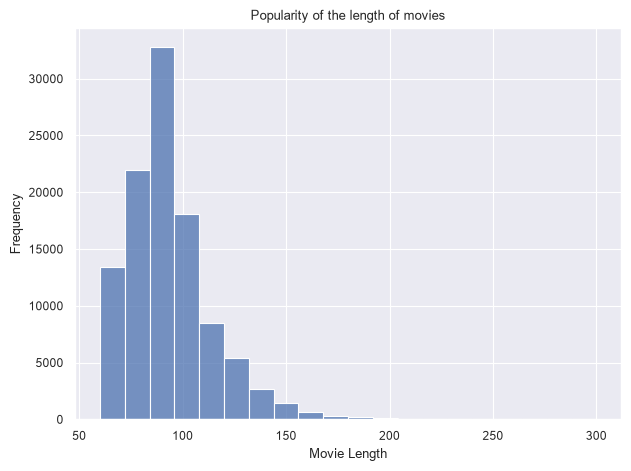

In [23]:
sns.set_context('notebook')
sns.set_theme('paper')
sns.set_style('darkgrid')

avg_rating = sns.histplot(
    data = directors,
    x='runtime_minutes',
    bins = 20
)

avg_rating.set(
    xlabel = 'Movie Length',
    ylabel = 'Frequency',
    title = 'Popularity of the length of movies'
)

plt.tight_layout()
plt.show()

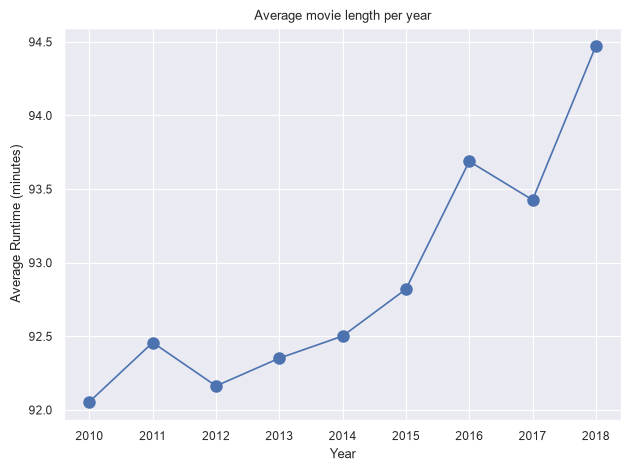

In [24]:
avg_length = directors.groupby('start_year')['runtime_minutes'].mean()

sns.set_context('notebook')
sns.set_theme('paper')
sns.set_style('darkgrid')

length_graph = avg_length.plot(
    kind='line',
    xlabel='Year',
    ylabel='Average Runtime (minutes)',
    title= 'Average movie length per year',
    marker = 'o',
    markersize = 8
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

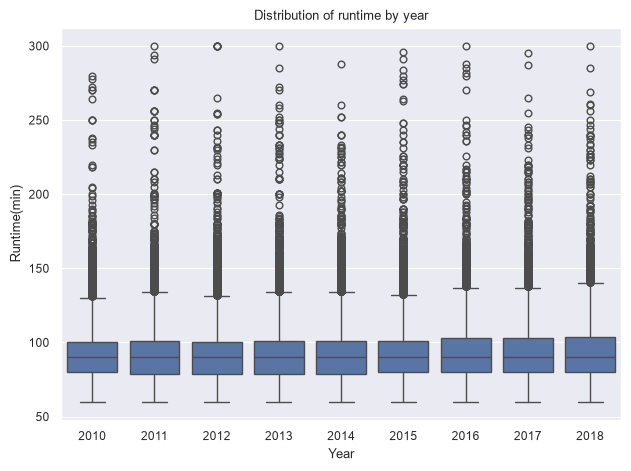

In [25]:
sns.set_theme('notebook')
sns.set_context('paper')
sns.set_style('darkgrid')

length_box = sns.boxplot(
    data = directors,
    x='start_year',
    y='runtime_minutes',
)

length_box.set(
    xlabel = 'Year',
    ylabel = 'Runtime(min)',
    title = 'Distribution of runtime by year' 
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
from pandasql import sqldf

pysqldf = lambda q : sqldf(q, globals())

In [27]:
q = """
SELECT primary_title, start_year, numvotes, averagerating
FROM directors
ORDER BY numvotes DESC, averagerating DESC
LIMIT 10
    """

top_10_movies = pysqldf(q)
top_10_movies

,primary_title,start_year,numvotes,averagerating
0,Inception,2010,1841066.0,8.8
1,The Dark Knight Rises,2012,1387769.0,8.4
2,Interstellar,2014,1299334.0,8.6
3,Django Unchained,2012,1211405.0,8.4
4,The Avengers,2012,1183655.0,8.1
5,The Wolf of Wall Street,2013,1035358.0,8.2
6,Shutter Island,2010,1005960.0,8.1
7,Guardians of the Galaxy,2014,948394.0,8.1
8,Deadpool,2016,820847.0,8.0
9,The Hunger Games,2012,795227.0,7.2


In [28]:
q = '''
SELECT director, AVG(numvotes) AS avg_numvotes ,AVG(averagerating) AS avg_rating_per_movie, COUNT(primary_title) AS number_of_movies
FROM directors
GROUP BY director
ORDER BY avg_numvotes DESC, avg_rating_per_movie DESC
LIMIT 10  
    '''

top_10_directors = pysqldf(q)
top_10_directors

,director,avg_numvotes,avg_rating_per_movie,number_of_movies
0,Christopher Nolan,1.248687e+06,8.425000,4
1,Tim Miller,8.208470e+05,8.000000,1
2,Anthony Russo,6.402283e+05,8.033333,3
3,Joss Whedon,6.215547e+05,7.533333,3
4,David Fincher,5.725833e+05,7.866667,3
5,Quentin Tarantino,5.499257e+05,8.333333,3
6,Ronnie Del Carmen,5.361810e+05,8.200000,1
7,Chris Buck,5.169980e+05,7.500000,1
8,Jennifer Lee,5.169980e+05,7.500000,1
9,J.J. Abrams,5.169633e+05,7.566667,3


In [29]:
q = '''
SELECT director, COUNT(primary_title) AS number_of_movies
FROM directors
WHERE director IS NOT NULL
GROUP BY director
ORDER BY number_of_movies DESC
LIMIT 10
    '''

most_movies_directors = pysqldf(q)
most_movies_directors


,director,number_of_movies
0,Omer Pasha,60
1,Gérard Courant,37
2,Nayato Fio Nuala,33
3,Michael Fredianelli,30
4,Eckhart Schmidt,29
5,David DeCoteau,26
6,William Winckler,25
7,Philip Gardiner,25
8,Sergey A.,24
9,Ernesto Aguilar,22


In [30]:
directors['genre_list'] = directors['genres'].str.split(',')
directors_expl = directors.explode('genre_list')
directors_expl['genre_list'] = directors_expl['genre_list'].str.strip()

In [31]:
movie_count = directors_expl['genre_list'].value_counts()
top_ten_genres = movie_count.head(10)
top_ten_genres

genre_list
Drama          41844
Documentary    32953
Comedy         22242
Thriller        9828
Horror          9811
Action          8316
Romance         8044
Biography       6683
Crime           5898
Adventure       5592
Name: count, dtype: int64

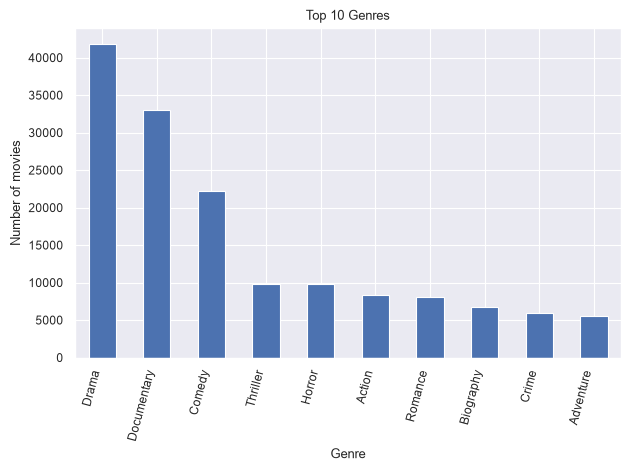

In [32]:
sns.set_theme('notebook')
sns.set_style('darkgrid')
sns.set_context('paper')

top_ten_genres.plot(
    kind='bar',
    xlabel='Genre',
    ylabel='Number of movies',
    title='Top 10 Genres'
)
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

In [35]:

movies_per_year = directors.groupby('start_year')['primary_title'].count()
movies_per_year

start_year
2010     9420
2011    10619
2012    10935
2013    11803
2014    12706
2015    12633
2016    12949
2017    12856
2018    11957
Name: primary_title, dtype: int64

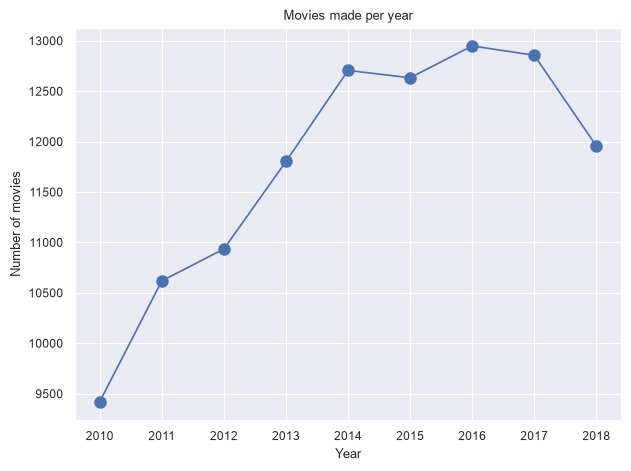

In [36]:
sns.set_theme('notebook')
sns.set_style('darkgrid')
sns.set_context('paper')

movies_per_year.plot(
    kind='line',
    xlabel='Year',
    ylabel='Number of movies',
    title='Movies made per year',
    marker='o',
    markersize=8
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
q = """
SELECT d1.start_year, d1.genre_list, COUNT(d1.genre_list) AS genre_count_per_year
FROM directors_expl d1
GROUP BY d1.start_year, d1.genre_list
HAVING genre_count_per_year = (
    SELECT MAX(group_count.cnt)
    FROM (
        SELECT COUNT(d2.genre_list) AS cnt
        FROM directors_expl d2
        WHERE d2.start_year = d1.start_year
        GROUP BY d2.genre_list
    ) AS group_count
)
ORDER BY d1.start_year ASC
    """

top_genre_year_volume = pysqldf(q)
top_genre_year_volume

,start_year,genre_list,genre_count_per_year
0,2010,Drama,3885
1,2011,Drama,4310
2,2012,Drama,4341
3,2013,Drama,4907
4,2014,Drama,5075
5,2015,Drama,5031
6,2016,Drama,4964
7,2017,Drama,4809
8,2018,Drama,4522


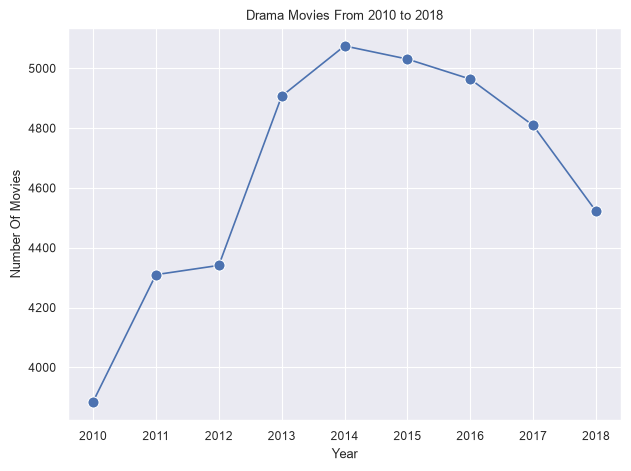

In [ ]:
sns.set_theme('notebook')
sns.set_style('darkgrid')
sns.set_context('paper')

drama_change = sns.lineplot(
    data=top_genre_year_volume,
    x='start_year',
    y='genre_count_per_year',
    marker='o',
    markersize = 8
)

drama_change.set(
    xlabel = 'Year',
    ylabel = 'Number Of Movies',
    title = 'Drama Movies From 2010 to 2018',
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
q = """
SELECT genre_list, AVG(averagerating) AS avg_rating
FROM directors_expl
WHERE genre_list IS NOT NULL
GROUP BY genre_list
ORDER BY avg_rating DESC
LIMIT 10
    """

top_10_rated_genres = pysqldf(q)
top_10_rated_genres

,genre_list,avg_rating
0,Game-Show,7.300000
1,Documentary,7.273473
2,News,7.243257
3,Biography,7.120252
4,Music,7.052462
5,History,7.011686
6,Sport,6.962055
7,War,6.556071
8,Musical,6.441791
9,Drama,6.367914


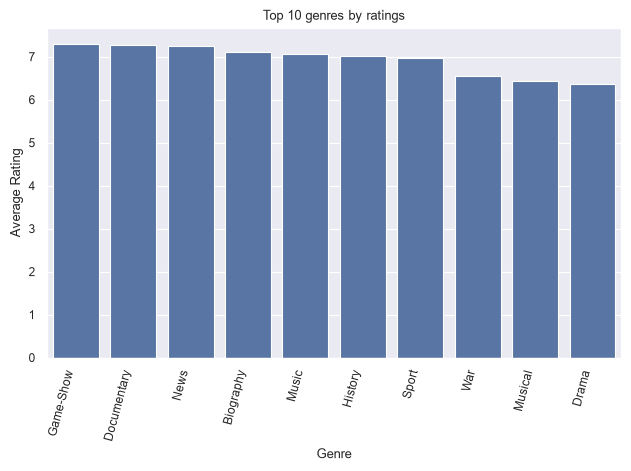

In [ ]:
sns.set_context('notebook')
sns.set_theme('paper')
sns.set_style('darkgrid')

sns.barplot(
    data=top_10_rated_genres,
    x='genre_list',
    y='avg_rating'
)
plt.xlabel('Genre')
plt.ylabel('Average Rating')
plt.title('Top 10 genres by ratings')
plt.xticks(rotation= 75, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
q = """
SELECT genre_list, averagerating, numvotes
FROM directors_expl
WHERE genre_list IS NOT NULL AND numvotes > 400
    """

avg_rate_numvotes = pysqldf(q)
avg_rate_numvotes

,genre_list,averagerating,numvotes
0,Drama,6.9,4517.0
1,Drama,6.8,451.0
2,Animation,7.8,584.0
3,Drama,7.8,584.0
4,History,7.8,584.0
...,...,...,...
35986,Drama,7.3,91349.0
35987,Mystery,7.3,91349.0
35988,Sci-Fi,7.3,91349.0
35989,Horror,4.1,600.0


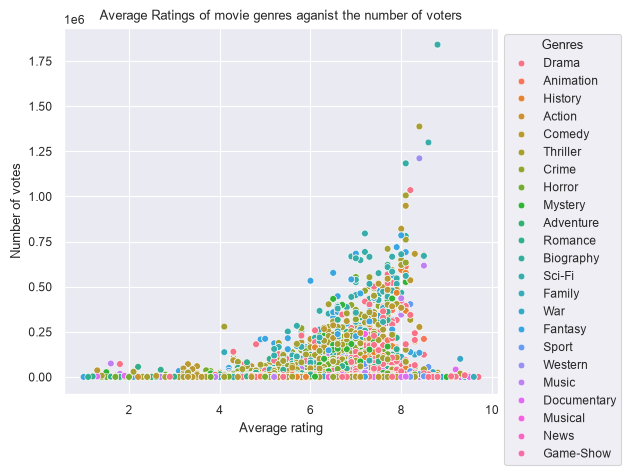

In [ ]:
sns.set_style('darkgrid')
sns.set_context('notebook')
sns.set_theme('paper')

corr = sns.scatterplot(
    data= avg_rate_numvotes,
    x='averagerating',
    y='numvotes',
    hue='genre_list'
)
sns.move_legend(corr,title='Genres' ,loc='upper left', bbox_to_anchor=(1,1))
corr.set(
    xlabel='Average rating',
    ylabel='Number of votes',
    title ='Average Ratings of movie genres aganist the number of voters'
)

plt.tight_layout()
plt.show()

In [ ]:
q = """
SELECT primary_title, COUNT(writers) AS number_of_writers
FROM writers
WHERE primary_title IS NOT NULL
GROUP BY primary_title
ORDER BY number_of_writers DESC
LIMIT 10
    """

writer_count = pysqldf(q)
writer_count

,primary_title,number_of_writers
0,50 Kisses,52
1,Our Footloose Remake,47
2,World of Death,46
3,Grindsploitation,43
4,Train Station,40
5,Mapa de recuerdos de Madrid,39
6,The 2017 CBS Diversity Sketch Comedy Showcase,38
7,ABCs of Death 2,33
8,60 Seconds to Die,33
9,Our RoboCop Remake,30


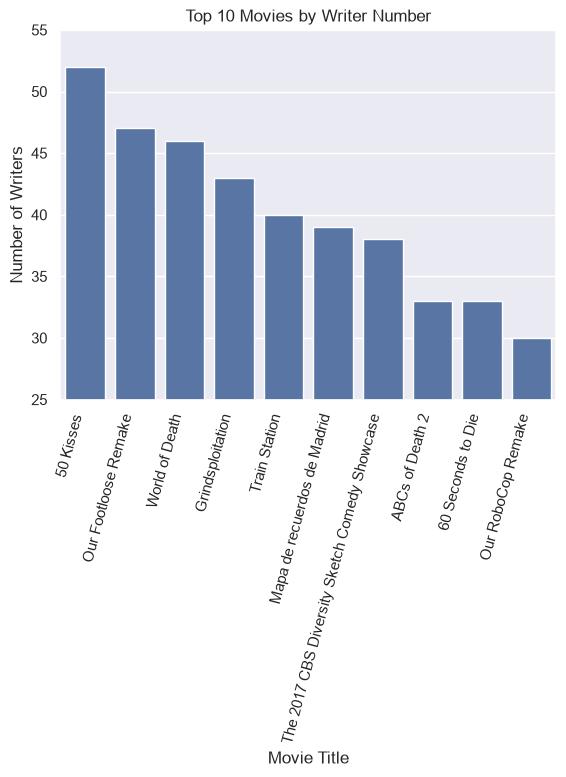

In [ ]:
sns.set_context('notebook')
sns.set_style('darkgrid')

write = sns.barplot(
    data= writer_count,
    x='primary_title',
    y='number_of_writers'
)
write.set(
    xlabel = 'Movie Title',
    ylabel = 'Number of Writers',
    title = 'Top 10 Movies by Writer Number'
)
plt.xticks(rotation=75, ha='right')
plt.ylim(25,55)
plt.show()

In [44]:

avg_rating_vs_runtime= directors[['averagerating', 'runtime_minutes']]
avg_rating_vs_runtime

,averagerating,runtime_minutes
0,7.0,175.0
1,6.9,122.0
3,6.5,80.0
4,6.5,80.0
5,NaN,75.0
...,...,...
158551,NaN,120.0
158553,NaN,102.0
158554,NaN,94.0
158555,NaN,84.0


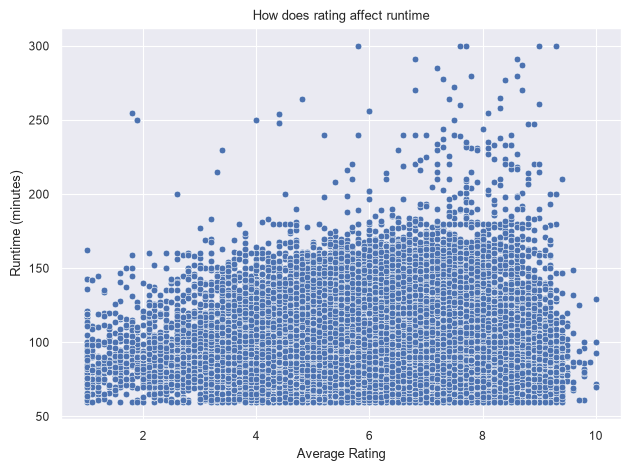

In [47]:
sns.set_context('notebook')
sns.set_theme('paper')
sns.set_style('darkgrid')

sns.scatterplot(
    data = avg_rating_vs_runtime,
    x = 'averagerating',
    y = 'runtime_minutes'
)

plt.xlabel('Average Rating')
plt.ylabel('Runtime (minutes)')
plt.title('How does rating affect runtime')
plt.tight_layout()
plt.show()